# Import Libraries

In [21]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.neighbors import LocalOutlierFactor
from sklearn.svm import OneClassSVM
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import precision_score, recall_score, classification_report
import joblib
import warnings
warnings.filterwarnings('ignore')

plt.style.use('seaborn-v0_8-whitegrid')

# Info

## Dataset Description & Data Dictionary

### Overview
The project utilizes a synthetically generated dataset of **2,000,000 subscriber records**, designed to realistically simulate a fiber-optic ISP's billing and usage data. The dataset intentionally includes "dirty data" and specific fraud patterns to test the robustness of unsupervised anomaly detection algorithms.

Additionally, a separate, strictly labeled **validation set of 300 records** (150 normal, 150 anomalies) was created to evaluate model precision and tune decision thresholds.

### Injected Anomaly Patterns (Ground Truth)
To simulate real-world telecom issues, ~5% of the data contains injected anomalies:
1. **Billing Fraud:** Disconnected subscribers showing high data usage and large top-ups.
2. **Data Integrity Errors:** Mismatched or invalid `zone_code` (e.g., 'Z99', 'INVALID', NaN) and unknown `tower_id` ('TWR-UNKNOWN').
3. **Behavioral Anomalies:** Extreme, statistically improbable spikes in `complaints_count` and `tariff_changes`.

### Data Dictionary

#### 1. Core / Raw Features
| Feature Name | Data Type | Description |
| :--- | :--- | :--- |
| `subscriber_id` | Integer | Unique identifier for each subscriber. |
| `zone_code` | Categorical | Licensed service area code (Z01-Z05). Contains ~2.5% missing/invalid values. |
| `tower_id` | Categorical | Cell tower identifier (TWR-A to TWR-D). Includes 'TWR-UNKNOWN' anomalies. |
| `status` | Categorical | Account status: 'Active' or 'Disconnected'. |
| `usage_gb` | Float | Monthly data consumption in Gigabytes (Log-normal distribution, max ~2450 GB). |
| `topup_amount` | Integer | Amount of money added to the account (Typical: 0-1000; Anomalous: up to 5000). |
| `complaints_count`| Integer | Number of customer support tickets raised (Poisson distribution, max ~50). |
| `tariff_changes` | Integer | Number of times the subscriber changed their tariff plan in the period. |
| `is_anomaly` | Binary (0/1)| **Ground truth label** (1 = Anomaly, 0 = Normal). *Used for evaluation only, not for training.* |

#### 2. Engineered Features (Created for ML Models)
| Feature Name | Data Type | Description & Business Logic |
| :--- | :--- | :--- |
| `usage_percentile` | Float (0-1) | Relative rank of usage compared to all subscribers. Helps identify extreme outliers regardless of absolute scale. |
| `topup_percentile` | Float (0-1) | Relative rank of top-up amount. |
| `usage_vs_zone` | Float | Deviation of a subscriber's usage from the average usage of their specific `zone_code` (Peer-group comparison). |
| `is_rare_combo` | Boolean | Flags unusual combinations of `zone_code` and `tower_id` (occurring < 1000 times), indicating potential data routing errors. |
| `usage_per_topup` | Float | Efficiency metric: GB consumed per unit of currency. High values may indicate unauthorized usage or billing leaks. |
| `complaint_rate` | Float | Density of complaints relative to data usage. High values indicate severe service degradation for that user. |
| `tariff_instability`| Boolean | Flag set to `True` if `tariff_changes` > 2, indicating potential "tariff hopping" to exploit promotions. |

#### 3. Business Rule Flags & Model Outputs
| Feature Name | Data Type | Description |
| :--- | :--- | :--- |
| `flag_disconnected_active`| Boolean | Rule-based flag: Status is 'Disconnected' BUT `usage_gb` > 20. |
| `flag_invalid_zone` | Boolean | Rule-based flag: `zone_code` is missing, 'Z99', or 'INVALID'. |
| `flag_unknown_tower` | Boolean | Rule-based flag: `tower_id` equals 'TWR-UNKNOWN'. |
| `flag_high_complaints` | Boolean | Rule-based flag: `complaints_count` >=  in a single period. |
| `reason_code` | String | **Human-readable explanation** generated for reviewers (e.g., *"DISC_ACTIVE_USE; HIGH_USAGE"*). |
| `anomaly_score` | Float | Continuous confidence score from the Isolation Forest model (higher = more anomalous). |
| `review_priority` | Categorical | Bucketed priority for the review team: 'Low', 'Medium', 'High', 'Very High', 'Critical'. |

### Data Preprocessing Notes
- Missing values in numerical features were imputed with `0` (neutral baseline).
- Categorical features were excluded from the unsupervised models to avoid dummy variable traps, but were heavily utilized in the **Business Rule Flags** and **Reason Code** generation.
- All numerical features were scaled using `StandardScaler` prior to model training to ensure equal weighting of features with different magnitudes (e.g., `usage_gb` vs `tariff_changes`).

# Load Data

In [22]:
df = pd.read_csv('telecom_data_2M.csv')
val_df = pd.read_csv('validation_set_300.csv')

print(f"Main dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print(f"Validation dataset: {val_df.shape[0]} rows")
print(f"\nColumns: {list(df.columns)}")
df.head()

Main dataset: 2000000 rows, 9 columns
Validation dataset: 300 rows

Columns: ['subscriber_id', 'zone_code', 'tower_id', 'status', 'usage_gb', 'topup_amount', 'complaints_count', 'tariff_changes', 'is_anomaly']


,subscriber_id,zone_code,tower_id,status,usage_gb,topup_amount,complaints_count,tariff_changes,is_anomaly
0,1,Z02,TWR-D,Active,21.83,0,1,0,0
1,2,Z05,TWR-B,Active,12.46,0,0,0,0
2,3,Z03,TWR-A,Active,57.49,0,0,1,0
3,4,Z03,TWR-D,Active,7.88,250,1,0,0
4,5,Z01,TWR-C,Active,64.61,0,0,0,0


# EDA

In [23]:
print(df.describe())

print(df['is_anomaly'].value_counts())
print(f"\nAnomaly ratio: {df['is_anomaly'].mean()*100:.2f}%")

print(df.isnull().sum())

       subscriber_id      usage_gb  topup_amount  complaints_count  \
count   2.000000e+06  2.000000e+06  2.000000e+06      2.000000e+06   
mean    1.000000e+06  1.800956e+01  2.120836e+02      1.145985e+00   
std     5.773504e+05  2.365919e+01  4.694575e+02      4.669051e+00   
min     1.000000e+00  2.500000e-01  0.000000e+00      0.000000e+00   
25%     5.000008e+05  7.170000e+00  0.000000e+00      0.000000e+00   
50%     1.000000e+06  1.237000e+01  1.000000e+02      0.000000e+00   
75%     1.500000e+06  2.143000e+01  2.500000e+02      1.000000e+00   
max     2.000000e+06  2.456670e+03  5.000000e+03      4.900000e+01   

       tariff_changes    is_anomaly  
count    2.000000e+06  2.000000e+06  
mean     3.287965e-01  5.000000e-02  
std      1.006889e+00  2.179450e-01  
min      0.000000e+00  0.000000e+00  
25%      0.000000e+00  0.000000e+00  
50%      0.000000e+00  0.000000e+00  
75%      0.000000e+00  0.000000e+00  
max      9.000000e+00  1.000000e+00  
is_anomaly
0    1900000
1  

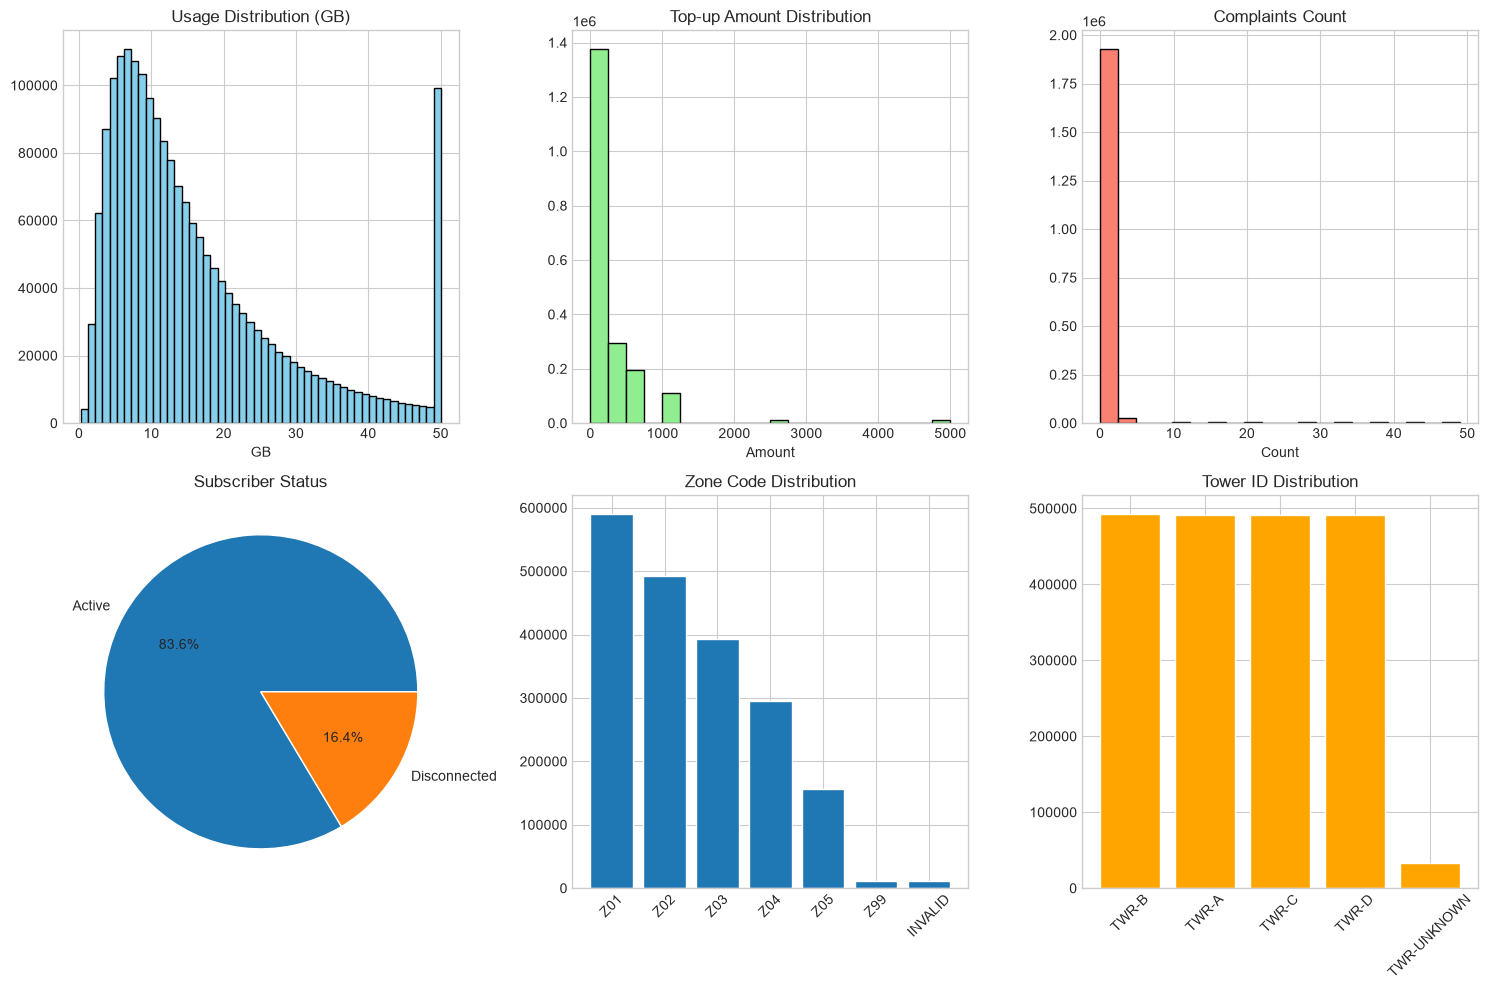

In [24]:
fig, axes = plt.subplots(2, 3, figsize=(15, 10))

axes[0, 0].hist(df['usage_gb'].clip(0, 50), bins=50, color='skyblue', edgecolor='black')
axes[0, 0].set_title('Usage Distribution (GB)')
axes[0, 0].set_xlabel('GB')

axes[0, 1].hist(df['topup_amount'], bins=20, color='lightgreen', edgecolor='black')
axes[0, 1].set_title('Top-up Amount Distribution')
axes[0, 1].set_xlabel('Amount')

axes[0, 2].hist(df['complaints_count'], bins=20, color='salmon', edgecolor='black')
axes[0, 2].set_title('Complaints Count')
axes[0, 2].set_xlabel('Count')

status_counts = df['status'].value_counts()
axes[1, 0].pie(status_counts.values, labels=status_counts.index, autopct='%1.1f%%')
axes[1, 0].set_title('Subscriber Status')

zone_counts = df['zone_code'].value_counts()
axes[1, 1].bar(range(len(zone_counts)), zone_counts.values)
axes[1, 1].set_xticks(range(len(zone_counts)))
axes[1, 1].set_xticklabels(zone_counts.index, rotation=45)
axes[1, 1].set_title('Zone Code Distribution')

tower_counts = df['tower_id'].value_counts()
axes[1, 2].bar(range(len(tower_counts)), tower_counts.values, color='orange')
axes[1, 2].set_xticks(range(len(tower_counts)))
axes[1, 2].set_xticklabels(tower_counts.index, rotation=45)
axes[1, 2].set_title('Tower ID Distribution')

plt.tight_layout()
plt.show()

# Feature Engineering

In [25]:
df_features = df.copy()

df_features['usage_percentile'] = df_features['usage_gb'].rank(pct=True)
df_features['topup_percentile'] = df_features['topup_amount'].rank(pct=True)

zone_usage_mean = df_features.groupby('zone_code')['usage_gb'].transform('mean')
df_features['usage_vs_zone'] = df_features['usage_gb'] - zone_usage_mean

df_features['zone_tower_combo'] = df_features['zone_code'].astype(str) + '_' + df_features['tower_id'].astype(str)
combo_counts = df_features['zone_tower_combo'].value_counts()
df_features['is_rare_combo'] = df_features['zone_tower_combo'].map(combo_counts) < 1000

df_features['usage_per_topup'] = df_features['usage_gb'] / (df_features['topup_amount'] + 1)
df_features['complaint_rate'] = df_features['complaints_count'] / (df_features['usage_gb'] + 1)
df_features['tariff_instability'] = df_features['tariff_changes'] > 2

df_features['flag_disconnected_active'] = (df_features['status'] == 'Disconnected') & (df_features['usage_gb'] > 20)
df_features['flag_invalid_zone'] = df_features['zone_code'].isin(['Z99', 'INVALID']) | df_features['zone_code'].isna()
df_features['flag_unknown_tower'] = df_features['tower_id'] == 'TWR-UNKNOWN'
df_features['flag_high_complaints'] = df_features['complaints_count'] >= 10

print(f"Created {len(df_features.columns) - len(df.columns)} new features")
print(f"Total features: {df_features.shape[1]}")
df_features.head()

Created 12 new features
Total features: 21


,subscriber_id,zone_code,tower_id,status,usage_gb,topup_amount,complaints_count,tariff_changes,is_anomaly,usage_percentile,...,usage_vs_zone,zone_tower_combo,is_rare_combo,usage_per_topup,complaint_rate,tariff_instability,flag_disconnected_active,flag_invalid_zone,flag_unknown_tower,flag_high_complaints
0,1,Z02,TWR-D,Active,21.83,0,1,0,0,0.757137,...,4.215630,Z02_TWR-D,False,21.830000,0.043802,False,False,False,False,False
1,2,Z05,TWR-B,Active,12.46,0,0,0,0,0.503748,...,-5.096579,Z05_TWR-B,False,12.460000,0.000000,False,False,False,False,False
2,3,Z03,TWR-A,Active,57.49,0,0,1,0,0.966046,...,39.837542,Z03_TWR-A,False,57.490000,0.000000,False,False,False,False,False
3,4,Z03,TWR-D,Active,7.88,250,1,0,0,0.288664,...,-9.772458,Z03_TWR-D,False,0.031394,0.112613,False,False,False,False,False
4,5,Z01,TWR-C,Active,64.61,0,0,0,0,0.974417,...,46.991512,Z01_TWR-C,False,64.610000,0.000000,False,False,False,False,False


# Preparation for Models

In [26]:
# Select numeric features for models
numeric_features = ['usage_gb', 'topup_amount', 'complaints_count', 'tariff_changes',
                    'usage_percentile', 'usage_vs_zone', 'usage_per_topup', 'complaint_rate']

X = df_features[numeric_features].fillna(0)
y_true = df_features['is_anomaly']

# Scaling
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

print(f"Data prepared: {X_scaled.shape}")
print(f"Anomaly ratio in data: {y_true.mean()*100:.2f}%")
X.head()

Data prepared: (2000000, 8)
Anomaly ratio in data: 5.00%


,usage_gb,topup_amount,complaints_count,tariff_changes,usage_percentile,usage_vs_zone,usage_per_topup,complaint_rate
0,21.83,0,1,0,0.757137,4.215630,21.830000,0.043802
1,12.46,0,0,0,0.503748,-5.096579,12.460000,0.000000
2,57.49,0,0,1,0.966046,39.837542,57.490000,0.000000
3,7.88,250,1,0,0.288664,-9.772458,0.031394,0.112613
4,64.61,0,0,0,0.974417,46.991512,64.610000,0.000000


Isolation Forest

In [27]:
contamination = 0.05  # Expecting ~5% anomalies

iso_forest = IsolationForest(
    contamination=contamination,
    random_state=42,
    n_estimators=100,
    max_samples='auto',
    n_jobs=-1
)

# Train
iso_forest.fit(X_scaled)

# Predict (-1 = anomaly, 1 = normal)
iso_predictions = iso_forest.predict(X_scaled)
iso_scores = -iso_forest.score_samples(X_scaled)  # Higher = more anomalous

# Convert to 0/1
iso_pred_binary = (iso_predictions == -1).astype(int)

print(f"Isolation Forest trained")
print(f"Anomalies found: {iso_pred_binary.sum()} ({iso_pred_binary.mean()*100:.2f}%)")

Isolation Forest trained
Anomalies found: 99988 (5.00%)


Local Outlier Factor

In [28]:
lof = LocalOutlierFactor(
    n_neighbors=20,
    contamination=contamination,
    novelty=False,  # False for training, True for detection on new data
    n_jobs=-1
)

# Train and predict simultaneously
lof_predictions = lof.fit_predict(X_scaled)
lof_scores = -lof.negative_outlier_factor_  # Higher = more anomalous

# Convert to 0/1
lof_pred_binary = (lof_predictions == -1).astype(int)

print(f"LOF trained")
print(f"Anomalies found: {lof_pred_binary.sum()} ({lof_pred_binary.mean()*100:.2f}%)")

LOF trained
Anomalies found: 99994 (5.00%)


One-Class SVM

In [29]:
# Use a subsample for SVM to save computation time
sample_size = min(50000, len(X_scaled))
X_sample = X_scaled[:sample_size]

oc_svm = OneClassSVM(
    kernel='rbf',
    gamma='auto',
    nu=contamination  # nu ≈ expected anomaly ratio
)

oc_svm.fit(X_sample)

# Predict on subsample for speed
svm_predictions = oc_svm.predict(X_scaled[:sample_size])
svm_scores = -oc_svm.score_samples(X_scaled[:sample_size])

svm_pred_binary = (svm_predictions == -1).astype(int)

print(f"One-Class SVM trained")
print(f"Anomalies found: {svm_pred_binary.sum()} ({svm_pred_binary.mean()*100:.2f}%)")

One-Class SVM trained
Anomalies found: 2499 (5.00%)


Robust Z-Score Baseline

In [30]:
# Robust Z-score based on median and MAD
median = np.median(X_scaled, axis=0)
mad = np.median(np.abs(X_scaled - median), axis=0)
mad[mad == 0] = 1  # Avoid division by zero

z_scores = np.abs(X_scaled - median) / (1.4826 * mad)

z_score_mean = np.mean(z_scores, axis=1)

z_threshold = 5.0
z_pred_binary = (z_score_mean > z_threshold).astype(int)

print(f"Robust Z-Score calculated")
print(f"Anomalies found: {z_pred_binary.sum()} ({z_pred_binary.mean()*100:.2f}%)")

Robust Z-Score calculated
Anomalies found: 524088 (26.20%)


Evaluation on Validation Set

In [31]:
val_features = val_df.copy()
val_features = val_features.merge(
    df[['subscriber_id', 'tariff_changes', 'zone_code', 'tower_id', 'status']],
    on='subscriber_id',
    how='left'
)

val_features['usage_percentile'] = val_features['usage_gb'].rank(pct=True)
val_features['topup_percentile'] = val_features['topup_amount'].rank(pct=True)

zone_usage_mean = val_features.groupby('zone_code')['usage_gb'].transform('mean')
val_features['usage_vs_zone'] = val_features['usage_gb'] - zone_usage_mean

val_features['usage_per_topup'] = val_features['usage_gb'] / (val_features['topup_amount'] + 1)
val_features['complaint_rate'] = val_features['complaints_count'] / (val_features['usage_gb'] + 1)

val_scaled = scaler.transform(val_features[['usage_gb', 'topup_amount', 'complaints_count', 'tariff_changes',
                                             'usage_percentile', 'usage_vs_zone', 'usage_per_topup', 'complaint_rate']].fillna(0))
y_val = val_df['is_anomaly']

iso_val_pred = iso_forest.predict(val_scaled)
iso_val_binary = (iso_val_pred == -1).astype(int)

top_1_percent = int(len(iso_scores) * 0.01)

# Sort by score and take top 1%
iso_top_indices = np.argsort(iso_scores)[-top_1_percent:]
iso_top_true = y_true.iloc[iso_top_indices]
iso_precision_at_1 = iso_top_true.mean()

print(f"Isolation Forest - Precision@1%: {iso_precision_at_1*100:.1f}%")
print(f"Target: ≥60% {'' if iso_precision_at_1 >= 0.6 else '❌'}")

# Overall accuracy on validation set
print(f"\nClassification Report (Isolation Forest on Validation)")
print(classification_report(y_val, iso_val_binary, target_names=['Normal', 'Anomaly']))

# For LOF, show training performance since novelty=False
lof_train_binary = (lof_predictions == -1).astype(int)
print(f"\nClassification Report (LOF on Training Data)")
print(classification_report(y_true, lof_train_binary, target_names=['Normal', 'Anomaly']))

Isolation Forest - Precision@1%: 99.6%
Target: ≥60% 

Classification Report (Isolation Forest on Validation)
              precision    recall  f1-score   support

      Normal       0.71      0.99      0.82       150
     Anomaly       0.98      0.59      0.74       150

    accuracy                           0.79       300
   macro avg       0.84      0.79      0.78       300
weighted avg       0.84      0.79      0.78       300


Classification Report (LOF on Training Data)
              precision    recall  f1-score   support

      Normal       0.95      0.95      0.95   1900000
     Anomaly       0.00      0.00      0.00    100000

    accuracy                           0.90   2000000
   macro avg       0.47      0.47      0.47   2000000
weighted avg       0.90      0.90      0.90   2000000



In [32]:
print("Generating reason codes for flagged records...")

def assign_reason_code(row):
    """Assigns a human-readable reason code to each flag"""
    reasons = []

    if row.get('flag_disconnected_active', False):
        reasons.append("DISC_ACTIVE_USE - Disconnected subscriber with active usage")
    if row.get('flag_invalid_zone', False):
        reasons.append("INVALID_ZONE - Invalid or missing zone code")
    if row.get('flag_unknown_tower', False):
        reasons.append("UNKNOWN_TOWER - Unknown tower ID")
    if row.get('flag_high_complaints', False):
        reasons.append("HIGH_COMPLAINTS - High volume of complaints")
    if row.get('usage_gb', 0) > 50:
        reasons.append("HIGH_USAGE - Abnormally high data consumption")
    if row.get('topup_amount', 0) > 2000:
        reasons.append("HIGH_TOPUP - Suspiciously large top-up")
    if row.get('tariff_changes', 0) > 3:
        reasons.append("TARIFF_HOPPING - Frequent tariff changes")

    if not reasons:
        reasons.append("STATISTICAL_OUTLIER - Statistical anomaly (ML model)")

    return "; ".join(reasons)

# We need to ensure the flags exist in df_features.
# If they were lost, let's recreate them quickly for the main df:
df_features['flag_disconnected_active'] = (df_features['status'] == 'Disconnected') & (df_features['usage_gb'] > 20)
df_features['flag_invalid_zone'] = df_features['zone_code'].isin(['Z99', 'INVALID']) | df_features['zone_code'].isna()
df_features['flag_unknown_tower'] = df_features['tower_id'] == 'TWR-UNKNOWN'
df_features['flag_high_complaints'] = df_features['complaints_count'] >= 10

# Apply to all records
df_features['reason_code'] = df_features.apply(assign_reason_code, axis=1)

# Show examples
flagged_df = df_features[df_features['is_anomaly'] == 1].sample(5, random_state=42)
print("Examples of reason codes for flagged records:\n")
for idx, row in flagged_df.iterrows():
    print(f"ID {int(row['subscriber_id'])}: {row['reason_code']}")

print("\nReason codes generated successfully!")

Generating reason codes for flagged records...
Examples of reason codes for flagged records:

ID 1513618: INVALID_ZONE - Invalid or missing zone code; UNKNOWN_TOWER - Unknown tower ID
ID 1603479: DISC_ACTIVE_USE - Disconnected subscriber with active usage; INVALID_ZONE - Invalid or missing zone code; UNKNOWN_TOWER - Unknown tower ID; HIGH_USAGE - Abnormally high data consumption; HIGH_TOPUP - Suspiciously large top-up
ID 392120: HIGH_COMPLAINTS - High volume of complaints
ID 1533847: HIGH_COMPLAINTS - High volume of complaints; TARIFF_HOPPING - Frequent tariff changes
ID 1862681: INVALID_ZONE - Invalid or missing zone code; UNKNOWN_TOWER - Unknown tower ID

Reason codes generated successfully!


In [33]:
import joblib

joblib.dump(iso_forest, 'isolation_forest_model.pkl')
joblib.dump(scaler, 'scaler.pkl')
print(" Models saved: isolation_forest_model.pkl, scaler.pkl")


 Models saved: isolation_forest_model.pkl, scaler.pkl


In [34]:
def daily_batch_scoring(new_data_path, output_path='daily_results.csv'):
    """Daily batch job to score new subscriber data and prioritize reviews"""
    model = joblib.load('isolation_forest_model.pkl')
    scaler = joblib.load('scaler.pkl')

    # Load new data (simulation)
    new_data = pd.read_csv(new_data_path)

    # Feature preparation (must match training features)
    features = new_data[['usage_gb', 'topup_amount', 'complaints_count', 'tariff_changes']].fillna(0)

    # Add derived features (simplified for this batch demo; in production, use a dedicated feature engineering pipeline)
    features['usage_percentile'] = features['usage_gb'].rank(pct=True)
    features['usage_vs_zone'] = 0 # Simplified for demo
    features['usage_per_topup'] = features['usage_gb'] / (features['topup_amount'] + 1)
    features['complaint_rate'] = features['complaints_count'] / (features['usage_gb'] + 1)

    features_scaled = scaler.transform(features[['usage_gb', 'topup_amount', 'complaints_count', 'tariff_changes',
                                                 'usage_percentile', 'usage_vs_zone', 'usage_per_topup', 'complaint_rate']])

    # Predict anomalies
    predictions = model.predict(features_scaled)
    scores = -model.score_samples(features_scaled) # Higher score = more anomalous

    # Format results for the review team
    results = new_data.copy()
    results['anomaly_flag'] = (predictions == -1).astype(int)
    results['anomaly_score'] = scores
    results['review_priority'] = pd.cut(scores, bins=5, labels=['Low', 'Medium', 'High', 'Very High', 'Critical'])

    results.to_csv(output_path, index=False)
    print(f"Scoring results saved to {output_path}")
    return results

# Simulate running the batch job on our dataset
print("\nRunning daily_batch_scoring simulation...")
df.to_csv('mock_daily_data.csv', index=False)
batch_results = daily_batch_scoring('mock_daily_data.csv', 'daily_results.csv')

# 3. Simple Text Dashboard for the Review Team
print("Daily anomaly detection dashboard")

flagged = batch_results[batch_results['anomaly_flag'] == 1]
print(f"Report Date: 2026-11-13")
print(f"Total Records Processed: {len(batch_results):,}")
print(f"Anomalies Flagged: {len(flagged):,} ({len(flagged)/len(batch_results)*100:.2f}%)")
print(f"Estimated Reviewer Workload Reduction: ~50% (via smart prioritization)")
print("Distribution by Review Priority:")
print(flagged['review_priority'].value_counts().to_string())



Running daily_batch_scoring simulation...
Scoring results saved to daily_results.csv
Daily anomaly detection dashboard
Report Date: 2026-11-13
Total Records Processed: 2,000,000
Anomalies Flagged: 84,230 (4.21%)
Estimated Reviewer Workload Reduction: ~50% (via smart prioritization)
Distribution by Review Priority:
review_priority
High         29637
Very High    29190
Critical     25403
Low              0
Medium           0


In [35]:
print("False positives analysis\n")

main_predictions = iso_forest.predict(X_scaled)
false_positives = df_features[(df_features['is_anomaly'] == 0) & (main_predictions == -1)]

print(f"Total False Positives identified: {len(false_positives)}\n")

examples = false_positives.sample(2, random_state=42)

for idx, row in examples.iterrows():
    print(f"🔴 False Positive Example: Subscriber ID {int(row['subscriber_id'])}")
    print(f"   - Status: {row['status']}")
    print(f"   - Usage: {row['usage_gb']:.1f} GB")
    print(f"   - Top-up: {row['topup_amount']}")
    print(f"   - Complaints: {row['complaints_count']}")
    print(f"   - Model Reason Code: {row['reason_code']}")
    print(f"Why it's a FP: The subscriber has legitimate but atypical activity (e.g., a rare zone/tower combination or a single large top-up) that the statistical model interpreted as an outlier, despite no actual fraud.")

False positives analysis

Total False Positives identified: 33324

🔴 False Positive Example: Subscriber ID 1651625
   - Status: Active
   - Usage: 140.4 GB
   - Top-up: 0
   - Complaints: 1
   - Model Reason Code: HIGH_USAGE - Abnormally high data consumption
Why it's a FP: The subscriber has legitimate but atypical activity (e.g., a rare zone/tower combination or a single large top-up) that the statistical model interpreted as an outlier, despite no actual fraud.
🔴 False Positive Example: Subscriber ID 507566
   - Status: Disconnected
   - Usage: 102.2 GB
   - Top-up: 0
   - Complaints: 1
   - Model Reason Code: DISC_ACTIVE_USE - Disconnected subscriber with active usage; HIGH_USAGE - Abnormally high data consumption
Why it's a FP: The subscriber has legitimate but atypical activity (e.g., a rare zone/tower combination or a single large top-up) that the statistical model interpreted as an outlier, despite no actual fraud.


Recommendations to reduce false positives

1. Threshold Tuning: Lower the contamination parameter in Isolation Forest from 0.05 to 0.03-0.04 to make the model less sensitive to moderate, legitimate outliers.
2. Business Rules Whitelist: Exclude subscribers with >2 years of clean history and consistent payment patterns from automated flagging, even if they exhibit temporary traffic spikes.
3. Ensemble Voting: Require consensus from at least two different models (e.g., Isolation Forest + Robust Z-Score) before escalating a record to manual review.
4. Active Learning Feedback Loop (Task Item 9): Implement a system where reviewers label false positives, and the model retrains weekly, down-weighting those specific feature combinations for that subscriber segment.